In [4]:
import numpy as np
import matplotlib.pyplot as plt


<h2><span style="color:blue;">Exercise 1.1</span> – Numerical Integration</h2>


Consider the approximation of the integral

$$
\int_0^1 f(x)\,dx
$$

by the **trapezoidal rule**

$$
\int_0^1 f(x)\,dx \approx T(h)
:= \sum_{i=0}^{N-1}\frac{h}{2}\left(f(x_i)+f(x_{i+1})\right),
$$

where

$$
x_i=ih,\qquad h=\frac{1}{N},
$$

as well as the **box rule**

$$
\int_0^1 f(x)\,dx \approx R(h)
:= \sum_{i=0}^{N-1}h f(x_i),
$$

where

$$
x_i=ih,\qquad h=\frac{1}{N}.
$$

## a) Implementation

Write one program that, given $N$ and a function $f$, returns $T(h)$, and another program that returns $R(h)$, with

$$
h=\frac{1}{N}.
$$

## b) Error Analysis

For

$$
f(x)=e^x
$$

and

$$
N(i)=2^{i+1},\qquad i=0,\ldots,9,
$$

set

$$
h(i)=\frac{1}{N(i)}.
$$

For these 10 values of $h$, compute the actual errors

$$
\operatorname{err}(i)
=\int_0^1 e^x\,dx-T(h(i))
=e-1-T(h(i)).
$$

Plot the **absolute value of the true error** in a double-logarithmic plot.

In Python notation, with the vectors `h` and `err` (both of length 10):

`matplotlib.pyplot.loglog(h, abs(err))`

**Questions:**

1. Does the true error behave like $Ch^2$?
2. Repeat the same procedure for the box rule.
3. What error behaviour do you observe for the box rule?

In [3]:

def trapez(f, N):
    h = 1 / N
    return sum(h / 2 * (f(i*h) + f((i+1)*h)) for i in range(N))

def box(f, N):
    h = 1 / N
    return sum(h * f(i*h) for i in range(N))


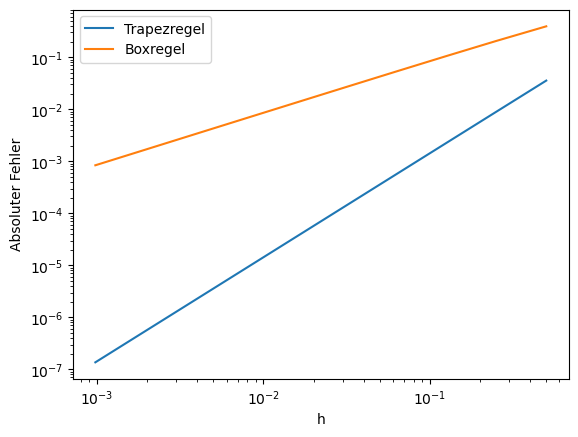

In [5]:
f = np.exp
I = np.e - 1

N = [2**(i+1) for i in range(10)]
h = [1/n for n in N]

err_T = [I - trapez(f, n) for n in N]
err_R = [I - box(f, n) for n in N]

plt.loglog(h, np.abs(err_T), label="Trapezregel")
plt.loglog(h, np.abs(err_R), label="Boxregel")

plt.xlabel("h")
plt.ylabel("Absoluter Fehler")
plt.legend()
plt.show()


In [6]:

print("h         Trapezfehler     Boxfehler")
for i in range(5):
    print(f"{h[i]:.5f}   {abs(err_T[i]):.8f}      {abs(err_R[i]):.8f}")


h         Trapezfehler     Boxfehler
0.50000   0.03564926      0.39392119
0.25000   0.00894008      0.20584515
0.12500   0.00223676      0.10515585
0.06250   0.00055930      0.05313701
0.03125   0.00013983      0.02670832



### Results

- **Trapezoidal rule:** The error behaves like $Ch^2$. Halving $h$ reduces the error by approximately a factor of 4 (convergence order 2).
- **Box rule:** The error behaves like $Ch$. Halving $h$ reduces the error by approximately a factor of 2 (convergence order 1).

In the log-log plot, this corresponds to slopes of approximately 2 and 1, respectively.

**Conclusion:** The trapezoidal rule converges faster and is more accurate for small $h$.



<h2><span style="color:blue;">Exercise 1.2</span> – Error Estimation for the Trapezoidal Rule</h2>


Consider the approximation of the integral

$$
\int_0^1 f(x)\,dx
$$

using the trapezoidal rule $T(h)$ from Exercise 1.1.

The goal is to construct an error estimator.

### a) Error Estimator

Assume that the error behaves like

$$
\int_0^1 f(x)\,dx - T(h) \approx Ch^2
$$

Determine the constant $C$ using the computed values $T(h)$ and $T(h/2)$.

The error estimator is then defined as

$$
E(h) = Ch^2
$$

### b) Numerical Implementation

Modify the program from Exercise 1.1 to also compute the error estimator $E(h)$.

For the test case $f(x) = e^x$, compute the ratio between the true and estimated errors:

$$
r(i) = \frac{\mathrm{err}(i)}{E(h(i))}
$$

Plot the ratio $r$ against $h$ using a semilogarithmic plot:

```python
plt.semilogx(h, r)
```



<h3 style="color:red;">Exercise 1.2 (a) – Error Estimator</h3>

We assume that the error behaves like:

$$
I-T(h)\approx Ch^2
$$

Replacing $h$ with $h/2$ gives:

$$
I-T(h/2)\approx \frac{Ch^2}{4}
$$

Subtracting both equations eliminates $I$:

$$
T(h/2)-T(h)\approx \frac{3}{4}Ch^2
$$

Solving for $C$:

$$
C\approx\frac{4(T(h/2)-T(h))}{3h^2}
$$

Therefore, the **error estimator** is:

$$
\boxed{E(h)=\frac{4}{3}\left(T(h/2)-T(h)\right)}
$$


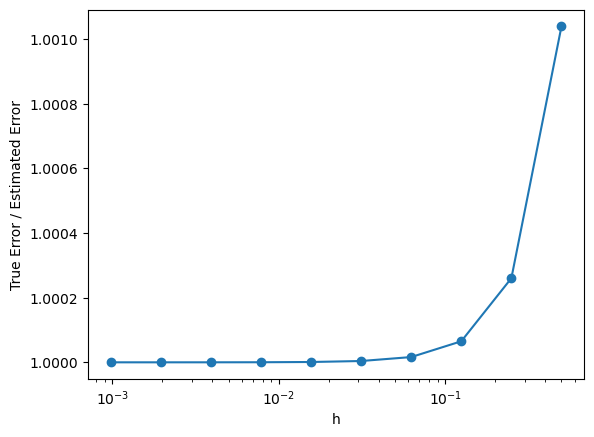

In [8]:

E = [4/3 * (trapez(f, 2*n) - trapez(f, n)) for n in N]
r = [err_T[i] / E[i] for i in range(10)]

plt.semilogx(h, r, "o-")
plt.xlabel("h")
plt.ylabel("True Error / Estimated Error")
plt.ticklabel_format(axis="y", style="plain", useOffset=False)
plt.show()



<h3 style="color:red;">Exercise 1.2 (b) – Conclusion</h3>

As $h$ decreases, the ratio $r(h)$ approaches 1.

This confirms that the estimated error approximates the true error very well for small step sizes.



<h2 style="color:blue;">Exercise 1.3 – Logarithmic Plots</h2>

Let $C, \alpha > 0$ and consider the function

$$
f(h) = Ch^\alpha
$$

Why is this function a straight line in a **log-log plot**? What is its slope?

Other popular plotting schemes are `semilogx` and `semilogy`.

Which one would you use to plot functions of the form

$$
f(N) = Ce^{-bN}
$$

How would you proceed if you suspect that a function has the form

$$
f(h) = Ce^{-b/h}
$$

What if you suspect

$$
f(h) = Ce^{-b/h^2}
$$



<h3 style="color:red;">Exercise 1.3 – Solution</h3>

### 1. Power Function

Given:

$$
f(h) = Ch^\alpha
$$

Taking the logarithm:

$$
\log(f(h)) = \log(C) + \alpha \log(h)
$$

This is a straight line of the form $y = mx + b$.

**Therefore, a log-log plot gives a straight line with slope $\alpha$.**

### 2. Exponential Function

Given:

$$
f(N) = Ce^{-bN}
$$

Taking the natural logarithm:

$$
\ln(f(N)) = \ln(C) - bN
$$

**Use `semilogy`**, since only the y-axis needs to be logarithmic.

### 3. Exponential Function with 1/h

Given:

$$
f(h) = Ce^{-b/h}
$$

Taking the natural logarithm:

$$
\ln(f(h)) = \ln(C) - b\frac{1}{h}
$$

**Use `semilogy` and plot $f(h)$ against $1/h$.**

### 4. Exponential Function with 1/h²

Given:

$$
f(h) = Ce^{-b/h^2}
$$

Taking the natural logarithm:

$$
\ln(f(h)) = \ln(C) - b\frac{1}{h^2}
$$

**Use `semilogy` and plot $f(h)$ against $1/h^2$.**

### Conclusion

- **Power functions $Ch^\alpha$:** Use `loglog`.
- **Exponential functions $Ce^{-bN}$:** Use `semilogy`.
- **Functions $Ce^{-b/h}$:** Use `semilogy` with $x = 1/h$.
- **Functions $Ce^{-b/h^2}$:** Use `semilogy` with $x = 1/h^2$.

The goal is to transform the function into a straight line to identify its convergence behavior.



<h2 style="color:blue;">Exercise 1.4 – Polynomial Interpolation</h2>

Let the data points be:

$$
(0,0), \quad (1,2), \quad (4,8)
$$

### a) Lagrange Interpolation

Write down the quadratic interpolating polynomial $p$ in Lagrange form:

$$
p(x)=\sum_{i=0}^{2} f_i \ell_i(x)
$$

### b) Linear System of Equations

The quadratic interpolating polynomial

$$
p(x)=a_0+a_1x+a_2x^2
$$

can also be determined by solving a linear system of equations for the coefficients $a_0,a_1,a_2$.

Formulate the system and solve for the coefficients.

### c) Numerical Verification with NumPy

Check your approximation $p(2)$ using the NumPy routines:

- `polyfit(x, f, n)`
- `polyval`

Note that `polyfit` also returns the coefficients $a_i$ from part (b). Compare the results.

<p style="color:green;"><strong>Note:</strong> The use of polyfit and polyval in polynomial interpolation should be viewed as a "quick and dirty" method, since polyfit uses the monomial basis $\{1,x,x^2,\ldots,x^n\}$ and is therefore numerically unsuitable for large $n$.</p>



<h3 style="color:red;">Exercise 1.4 (a) – Lagrange Interpolation</h3>

Given the data points:

$$
(x_0,f_0)=(0,0),\quad (x_1,f_1)=(1,2),\quad (x_2,f_2)=(4,8)
$$

The Lagrange interpolation polynomial is:

$$
p(x)=\sum_{i=0}^{2}f_i\ell_i(x)
$$

The Lagrange basis polynomials are:

$$
\ell_0(x)=\frac{(x-1)(x-4)}{(0-1)(0-4)}=\frac{(x-1)(x-4)}{4}
$$

$$
\ell_1(x)=\frac{x(x-4)}{(1-0)(1-4)}=-\frac{x(x-4)}{3}
$$

$$
\ell_2(x)=\frac{x(x-1)}{(4-0)(4-1)}=\frac{x(x-1)}{12}
$$

Substituting the values:

$$
p(x)=0\cdot\ell_0(x)+2\cdot\ell_1(x)+8\cdot\ell_2(x)
$$

$$
p(x)=-\frac{2x(x-4)}{3}+\frac{2x(x-1)}{3}
$$

Therefore:

$$
\boxed{p(x)=2x}
$$

<h3 style="color:red;">Exercise 1.4 (b) – Linear System</h3>

We use:

$$
p(x)=a_0+a_1x+a_2x^2
$$

Substituting the three data points gives:

$$
\begin{aligned}
a_0 &= 0\\
a_0+a_1+a_2 &= 2\\
a_0+4a_1+16a_2 &= 8
\end{aligned}
$$

In matrix form:

$$
\begin{pmatrix}
1&0&0\\
1&1&1\\
1&4&16
\end{pmatrix}
\begin{pmatrix}
a_0\\a_1\\a_2
\end{pmatrix}
=
\begin{pmatrix}
0\\2\\8
\end{pmatrix}
$$

Solving the system:

$$
\boxed{a_0=0,\quad a_1=2,\quad a_2=0}
$$

Thus:

$$
\boxed{p(x)=2x}
$$

<h3 style="color:red;">Exercise 1.4 (c) – NumPy Verification</h3>

We use `polyfit` to compute the coefficients and `polyval` to evaluate the polynomial at $x=2$.


In [10]:

A = np.array([[1, 0, 0],
              [1, 1, 1],
              [1, 4, 16]])

b = np.array([0, 2, 8])

a = np.linalg.solve(A, b)
print("Coefficients:", a)


Coefficients: [ 0.  2. -0.]


In [9]:

x = [0, 1, 4]
f = [0, 2, 8]

a = np.polyfit(x, f, 2)
print("Coefficients:", a)
print("p(2) =", np.polyval(a, 2))


Coefficients: [5.97842919e-16 2.00000000e+00 5.12790050e-16]
p(2) = 4.0000000000000036



<h2 style="color:blue;">Exercise 1.5 – Neville Scheme and Extrapolation</h2>

### a) Interpolating Polynomial

Write a routine that takes two vectors `x` and `f` as input, containing the knots and corresponding function values (both of length $n+1$).

The routine should return the value of the interpolating polynomial at $x=0$, i.e., $p(0)$, where $p$ is a polynomial of degree at most $n$ satisfying

$$
p(x_i)=f_i \quad \text{for all } i.
$$

To simplify the implementation, you may use `polyfit` and `polyval`.

### b) Neville Scheme

Using the routine from (a), write a function that takes a function $f$ and two integers $m,n\in\mathbb{N}_0$ as input.

The output should be a matrix

$$
N\in\mathbb{R}^{(m+1)\times(n+1)}
$$

with entries

$$
N_{j,k}=p_{j,k}(0),
\quad j=0,\ldots,m,\quad k=0,\ldots,n.
$$

Here, $p_{j,k}$ is the polynomial of degree at most $k$ interpolating the data

$$
(h_{j+\ell},f(h_{j+\ell})),\quad \ell=0,\ldots,k,
$$

where

$$
h_i=2^{-i}.
$$

<p style="color:green;"><strong>Remark:</strong> This matrix $N$ is called the Neville scheme for interpolation, although it is usually constructed differently. This will be covered later in class.</p>

### c) Convergence Analysis

Apply your routine from (b) to the function

$$
f(h)=\frac{e^h-1}{h}
$$

using

$$
m=10,\qquad n=2.
$$

The columns of $N$ are expected to converge to

$$
\lim_{h\to0}f(h)=1.
$$

To verify this, create a log-log plot of

$$
h \quad \text{vs.} \quad |N(:,k)-1|
$$

for all three columns $k=1,2,3$.

**Question:** What convergence behavior do you observe for the three graphs?


In [11]:
def interp0(x, f):
    p = np.polyfit(x, f, len(x)-1)
    return np.polyval(p, 0)


In [12]:

def neville(f, m, n):
    N = np.zeros((m+1, n+1))

    for j in range(m+1):
        for k in range(n+1):
            h = 2.0**(-np.arange(j, j+k+1))
            N[j, k] = interp0(h, f(h))

    return N


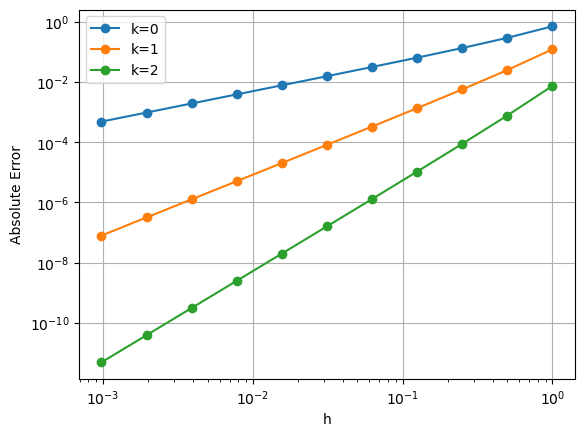

In [13]:

def f(h):
    return np.expm1(h) / h

N = neville(f, 10, 2)
h = 2.0**(-np.arange(11))

for k in range(3):
    plt.loglog(h, abs(N[:, k] - 1), "o-", label=f"k={k}")

plt.xlabel("h")
plt.ylabel("Absolute Error")
plt.legend()
plt.grid()
plt.show()



<h3 style="color:red;">Exercise 1.5 – Conclusion</h3>

All three columns converge to the limit $1$ as $h \to 0$.

- **k = 0:** Constant interpolation, error $O(h)$, slope 1.
- **k = 1:** Linear interpolation, error $O(h^2)$, slope 2.
- **k = 2:** Quadratic interpolation, error $O(h^3)$, slope 3.

**Conclusion:** Higher-degree polynomial extrapolation leads to faster convergence for this smooth function.



<h2 style="color:blue;">Exercise 1.6 – Polynomial Interpolation and Integration</h2>

Let the function be:

$$
f(x)=\frac{x^2}{1+x^2}
$$

Use the knots

$$
x_0=0,\quad x_1=1,\quad x_2=2
$$

with corresponding function values $f_i=f(x_i)$.

### a) Interpolation Polynomials

Compute:

- The **linear interpolation polynomial** using $x_0$ and $x_3$.
- The **cubic interpolation polynomial** using all knots.

### b) Numerical Integration

Use both interpolation polynomials to approximate the integral:

$$
\int_0^3 f(x)\,dx
$$

Calculate the errors of both approximations.


In [14]:
x = np.array([0, 1, 2, 3])
f = x**2 / (1 + x**2)

p1 = np.polyfit(x[[0, 3]], f[[0, 3]], 1)
p3 = np.polyfit(x, f, 3)

I1 = np.polyval(np.polyint(p1), 3)
I3 = np.polyval(np.polyint(p3), 3)
I = 3 - np.arctan(3)

print("Linear coefficients:", np.round(p1, 8))
print("Cubic coefficients:", np.round(p3, 8))
print("Exact integral:", I)
print("Linear approximation:", I1, "Error:", abs(I-I1))
print("Cubic approximation:", I3, "Error:", abs(I-I3))


Linear coefficients: [0.3 0. ]
Cubic coefficients: [-0.  -0.1  0.6  0. ]
Exact integral: 1.7509542276017456
Linear approximation: 1.3499999999999996 Error: 0.4009542276017459
Cubic approximation: 1.8000000000000003 Error: 0.049045772398254694



<h3 style="color:red;">Exercise 1.6 – Solution</h3>

Assuming the missing knot is $x_3=3$.

### a) Interpolation Polynomials

The function values are:

$$
f(0)=0,\quad f(1)=0.5,\quad f(2)=0.8,\quad f(3)=0.9
$$

**Linear interpolation (2 knots):**

Using $x_0=0$ and $x_3=3$:

$$
p_1(x)=a_0+a_1x
$$

$$
p_1(0)=0 \Rightarrow a_0=0
$$

$$
p_1(3)=0.9 \Rightarrow 3a_1=0.9 \Rightarrow a_1=0.3
$$

Therefore:

$$
\boxed{p_1(x)=0.3x}
$$

**Cubic interpolation (4 knots):**

Using all four knots:

$$
p_3(x)=a_0+a_1x+a_2x^2+a_3x^3
$$

The interpolation conditions give:

$$
\begin{aligned}
a_0 &= 0\\
a_0+a_1+a_2+a_3 &= 0.5\\
a_0+2a_1+4a_2+8a_3 &= 0.8\\
a_0+3a_1+9a_2+27a_3 &= 0.9
\end{aligned}
$$

Solving the system gives:

$$
a_0=0,\quad a_1=0.6,\quad a_2=-0.1,\quad a_3=0
$$

Therefore:

$$
\boxed{p_3(x)=0.6x-0.1x^2}
$$

The cubic coefficient is zero, so the polynomial is actually quadratic.

### b) Numerical Integration

The exact integral is:

$$
I=\int_0^3\frac{x^2}{1+x^2}\,dx
=\left[x-\arctan(x)\right]_0^3
$$

$$
\boxed{I=3-\arctan(3)\approx1.750954}
$$

**Linear approximation:**

$$
I_1=\int_0^3 0.3x\,dx
=\left[0.15x^2\right]_0^3
=\boxed{1.35}
$$

$$
|I-I_1|\approx0.400954
$$

**Cubic approximation:**

$$
I_3=\int_0^3(0.6x-0.1x^2)\,dx
$$

$$
I_3=\left[0.3x^2-\frac{0.1}{3}x^3\right]_0^3
=\boxed{1.8}
$$

$$
|I-I_3|\approx0.049046
$$

### Conclusion

The interpolation using four knots gives a significantly smaller integration error than the linear interpolation using two knots.
